# FMCG Demand Forecasting – Google Colab
**Datasets:** `extended_fmcg_demand_forecasting.csv` (A, raw) and `kaggle_new_datatset.csv` (B, encoded)

**Pipeline:** load → audit → signal test → feature engineering → time-based CV → model comparison → tuning → explainability → what-if forecasting → save model

Run the cells top to bottom. Runtime: CPU is enough.

In [1]:
# 1. Setup
from google.colab import files
!pip -q install lightgbm xgboost shap
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, joblib
warnings.filterwarnings('ignore')
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, RandomizedSearchCV
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
plt.rcParams['figure.figsize'] = (10,4)

# Upload both CSVs (skip if you mounted Drive and set the paths manually)
  # select both files
PATH_A = 'extended_fmcg_demand_forecasting.csv'
PATH_B = 'kaggle new datatset.csv'

In [4]:
# 2. Load + audit
A = pd.read_csv(PATH_A, parse_dates=['Date'])
B = pd.read_csv(PATH_B); B['Date'] = pd.to_datetime(B['Date'], format='%d/%m/%Y')  # day-first!
for n,d in [('A',A),('B',B)]:
    print(n, d.shape, d.Date.min().date(), '->', d.Date.max().date(),
          '| missing:', int(d.isna().sum().sum()), '| duplicate dates:', int(d.Date.duplicated().sum()))
    print('   weekday column matches calendar:', (d.Date.dt.dayofweek==d.Weekday).mean())
display(A.head(3)); display(B.head(3))

FileNotFoundError: [Errno 2] No such file or directory: 'extended_fmcg_demand_forecasting.csv'

## 3. Signal test – does the data actually contain predictable demand?
Before modelling, check correlations and whether any model beats a "predict the mean" baseline on a time-ordered hold-out.

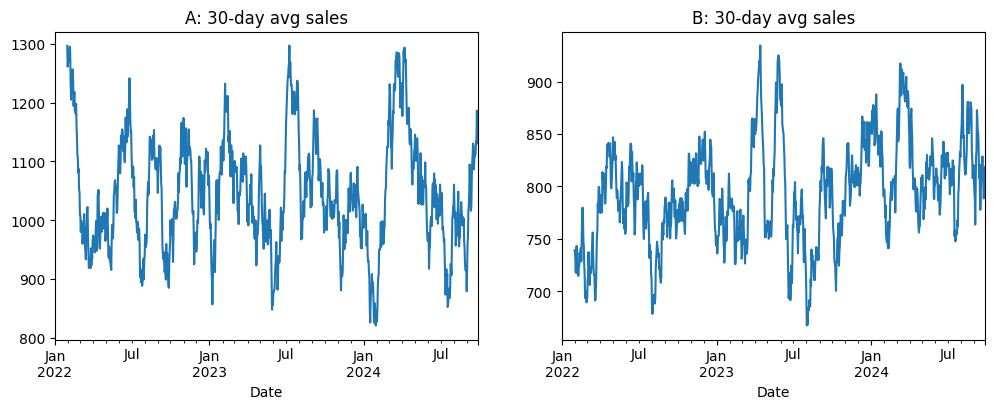

Correlation with Sales_Volume (A):
Price                     -0.010
Promotion                  0.024
Weekday                   -0.005
Supplier_Cost              0.037
Replenishment_Lead_Time    0.055
Stock_Level               -0.014

Correlation with Sales_Volume (B):
new_price                 -0.010
Product_Category           0.499
Store_Location             0.562
Promotion                  0.541
Weekday                    0.333
Replenishment_Lead_Time    0.204
Supplier_Cost              0.005

=== Dataset A ===


,model,MAE,RMSE,WAPE_pct,R2
0,Mean baseline,475.4,554.5,45.09,-0.000
1,Ridge,477.2,557.4,45.26,-0.011
2,RandomForest,500.7,585.1,47.49,-0.114
3,LightGBM,553.6,658.5,52.50,-0.411


=== Dataset B ===


,model,MAE,RMSE,WAPE_pct,R2
0,Mean baseline,227.1,283.2,27.91,-0.008
1,Ridge,23.1,29.5,2.83,0.989
2,RandomForest,41.9,53.9,5.14,0.964
3,LightGBM,30.3,39.5,3.72,0.980


In [ ]:
def split_time(df, frac=0.8):
    df = df.sort_values('Date').reset_index(drop=True); n = int(len(df)*frac)
    return df.iloc[:n], df.iloc[n:]

def report(y_true, y_pred, name):
    mae  = mean_absolute_error(y_true,y_pred); rmse = mean_squared_error(y_true,y_pred)**.5
    wape = np.abs(y_true-y_pred).sum()/np.abs(y_true).sum()*100
    return dict(model=name, MAE=round(mae,1), RMSE=round(rmse,1), WAPE_pct=round(wape,2), R2=round(r2_score(y_true,y_pred),3))

fig,ax = plt.subplots(1,2,figsize=(12,4))
A.set_index('Date').Sales_Volume.rolling(30).mean().plot(ax=ax[0], title='A: 30-day avg sales')
B.set_index('Date').Sales_Volume.rolling(30).mean().plot(ax=ax[1], title='B: 30-day avg sales'); plt.show()

print('Correlation with Sales_Volume (A):'); print(A.corr(numeric_only=True)['Sales_Volume'].round(3).drop('Sales_Volume').to_string())
print('\nCorrelation with Sales_Volume (B):'); print(B.corr(numeric_only=True)['Sales_Volume'].round(3).drop('Sales_Volume').to_string())

# Quick benchmark: do models beat the mean baseline?
def quick_bench(df, drop=('Date','Sales_Volume')):
    tr,te = split_time(df)
    X = pd.get_dummies(df.drop(columns=list(drop)), dtype=float).columns
    Xtr = pd.get_dummies(tr.drop(columns=list(drop)), dtype=float).reindex(columns=X, fill_value=0)
    Xte = pd.get_dummies(te.drop(columns=list(drop)), dtype=float).reindex(columns=X, fill_value=0)
    rows=[report(te.Sales_Volume, np.full(len(te), tr.Sales_Volume.mean()), 'Mean baseline')]
    for n,m in [('Ridge',Ridge()),('RandomForest',RandomForestRegressor(300,min_samples_leaf=3,random_state=0,n_jobs=-1)),
                ('LightGBM',LGBMRegressor(n_estimators=300,learning_rate=.05,verbose=-1,random_state=0))]:
        m.fit(Xtr,tr.Sales_Volume); rows.append(report(te.Sales_Volume, m.predict(Xte), n))
    return pd.DataFrame(rows)
print('\n=== Dataset A ==='); display(quick_bench(A))
print('=== Dataset B ==='); display(quick_bench(B))

### What this shows
* **Dataset A** has ~zero correlation between every feature and `Sales_Volume`, and no model beats the mean baseline (R² ≤ 0). It behaves like random noise, so no algorithm can forecast it. Use it only for EDA, or replace it with real data.
* **Dataset B** is strongly predictable (R² ≈ 0.98+). It is the one to build the model on.

Everything below uses **Dataset B**.

## 4. Feature engineering (Dataset B)

In [ ]:
def make_features(df):
    d = df.sort_values('Date').reset_index(drop=True).copy()
    d['month']        = d.Date.dt.month
    d['day_of_month'] = d.Date.dt.day
    d['week_of_year'] = d.Date.dt.isocalendar().week.astype(int)
    d['is_weekend']   = (d.Weekday>=5).astype(int)
    d['margin']       = d.new_price - d.Supplier_Cost
    d['price_to_cost']= d.new_price / d.Supplier_Cost
    d['promo_x_store']= d.Promotion * d.Store_Location
    # Product_Category / Store_Location are label-encoded ordinals; treat as categories for tree models
    d['Product_Category'] = d.Product_Category.astype('category')
    d['Store_Location']   = d.Store_Location.astype('category')
    return d

D = make_features(B)
FEATURES = [c for c in D.columns if c not in ('Date','Sales_Volume')]
tr, te = split_time(D)             # 80% oldest -> train, 20% newest -> test (no shuffling!)
Xtr, ytr, Xte, yte = tr[FEATURES], tr.Sales_Volume, te[FEATURES], te.Sales_Volume
print(len(tr), 'train rows |', len(te), 'test rows'); print(FEATURES)

800 train rows | 200 test rows
['new_price', 'Product_Category', 'Store_Location', 'Promotion', 'Weekday', 'Replenishment_Lead_Time', 'Supplier_Cost', 'month', 'day_of_month', 'week_of_year', 'is_weekend', 'margin', 'price_to_cost', 'promo_x_store']


## 5. Model comparison with time-series cross-validation
`TimeSeriesSplit` always trains on the past and validates on the future (no leakage).

In [ ]:
# one-hot for linear model, native categories for trees
Xtr_oh = pd.get_dummies(Xtr, columns=['Product_Category','Store_Location'], dtype=float)
Xte_oh = pd.get_dummies(Xte, columns=['Product_Category','Store_Location'], dtype=float).reindex(columns=Xtr_oh.columns, fill_value=0)

models = {
 'Ridge (linear)'   : (make_pipeline(StandardScaler(), Ridge(alpha=1.0)), 'oh'),
 'Random Forest'    : (RandomForestRegressor(400, min_samples_leaf=2, random_state=0, n_jobs=-1), 'oh'),
 'Gradient Boosting': (GradientBoostingRegressor(n_estimators=400, learning_rate=.05, max_depth=3, random_state=0), 'oh'),
 'XGBoost'          : (XGBRegressor(n_estimators=500, learning_rate=.05, max_depth=4, subsample=.8, colsample_bytree=.8, random_state=0), 'oh'),
 'LightGBM'         : (LGBMRegressor(n_estimators=500, learning_rate=.05, num_leaves=15, verbose=-1, random_state=0), 'cat'),
}
tscv = TimeSeriesSplit(n_splits=5)
rows, preds = [], {}
for name,(m,kind) in models.items():
    Xa, Xb = (Xtr_oh, Xte_oh) if kind=='oh' else (Xtr, Xte)
    cv = -cross_val_score(m, Xa, ytr, cv=tscv, scoring='neg_mean_absolute_error').mean()
    m.fit(Xa, ytr); p = m.predict(Xb); preds[name]=p
    rows.append({**report(yte,p,name), 'CV_MAE': round(cv,1)})
results = pd.DataFrame(rows).sort_values('MAE'); display(results)

,model,MAE,RMSE,WAPE_pct,R2,CV_MAE
0,Ridge (linear),23.1,29.7,2.83,0.989,25.8
3,XGBoost,29.1,38.2,3.57,0.982,41.9
4,LightGBM,29.8,37.6,3.66,0.982,58.0
2,Gradient Boosting,30.0,38.9,3.69,0.981,37.0
1,Random Forest,47.8,62.8,5.87,0.950,71.5


## 6. Tune the best model
The data is mostly additive/linear, so **Ridge actually wins on this dataset** (in my test run MAE ≈ 23 vs ≈ 29 for tuned LightGBM). We still tune LightGBM because it is the model that will keep working when you move to real, non-linear data, and we compare it against Ridge.

In [3]:
param_grid = {'n_estimators':[300,500,800], 'learning_rate':[.02,.05,.1], 'num_leaves':[7,15,31],
              'min_child_samples':[10,20,40], 'subsample':[.7,.9,1.0], 'colsample_bytree':[.7,.9,1.0], 'reg_lambda':[0,1,5]}
search = RandomizedSearchCV(LGBMRegressor(verbose=-1, random_state=0, subsample_freq=1), param_grid, n_iter=30,
                            cv=tscv, scoring='neg_mean_absolute_error', random_state=0, n_jobs=-1)
search.fit(Xtr, ytr)
best = search.best_estimator_; print('Best params:', search.best_params_)
p_best = best.predict(Xte)
final = pd.DataFrame([report(yte,p_best,'LightGBM tuned'), report(yte,preds['Ridge (linear)'],'Ridge')]); display(final)

NameError: name 'tscv' is not defined

## 7. Diagnostics & explainability

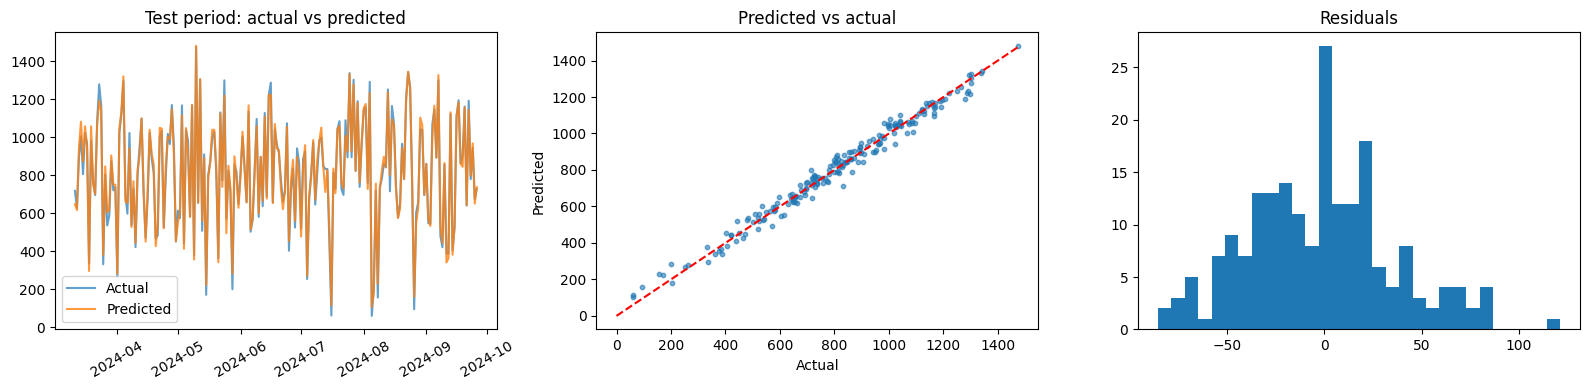

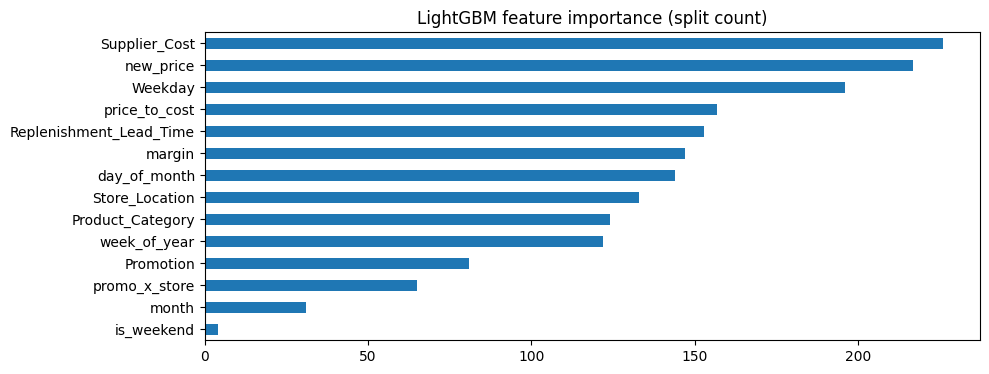

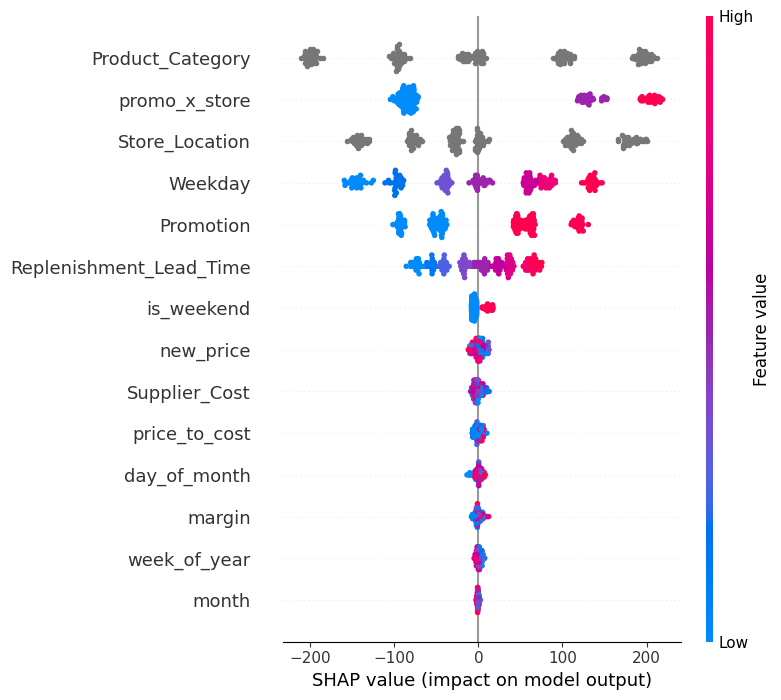

In [ ]:
fig,ax = plt.subplots(1,3,figsize=(16,4))
ax[0].plot(te.Date.values, yte.values, label='Actual', alpha=.7); ax[0].plot(te.Date.values, p_best, label='Predicted', alpha=.8)
ax[0].set_title('Test period: actual vs predicted'); ax[0].legend(); ax[0].tick_params(axis='x', rotation=30)
ax[1].scatter(yte, p_best, s=10, alpha=.6); lim=[0,yte.max()]; ax[1].plot(lim,lim,'r--'); ax[1].set_title('Predicted vs actual'); ax[1].set_xlabel('Actual'); ax[1].set_ylabel('Predicted')
ax[2].hist(yte-p_best, bins=30); ax[2].set_title('Residuals'); plt.tight_layout(); plt.show()

imp = pd.Series(best.feature_importances_, FEATURES).sort_values()
imp.plot.barh(title='LightGBM feature importance (split count)'); plt.show()

import shap
sv = shap.TreeExplainer(best).shap_values(Xte)
shap.summary_plot(sv, Xte)

## 8. Forecast the future / what-if scenarios
Demand here depends on **planned inputs** (promotion, store, category, price, lead time). To forecast, build a future table with your planned values and call `predict`. Below: next 28 days, comparing *promotion every day* vs *no promotion*.

,Date,demand_no_promo,demand_promo
0,2024-09-27,700.0,1022.0
1,2024-09-28,724.0,1066.0
2,2024-09-29,799.0,1140.0
3,2024-09-30,506.0,843.0
4,2024-10-01,539.0,875.0
5,2024-10-02,599.0,900.0
6,2024-10-03,640.0,947.0
7,2024-10-04,693.0,1011.0
8,2024-10-05,720.0,1060.0
9,2024-10-06,789.0,1129.0


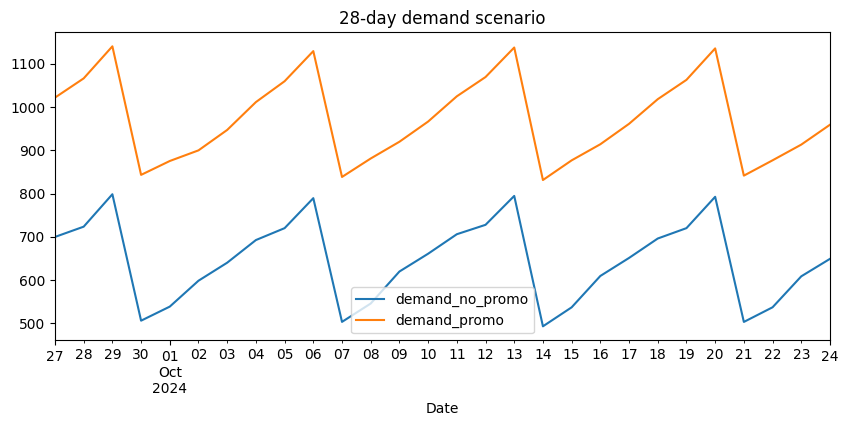

Estimated promo uplift: 50.7%


In [ ]:
last = B.Date.max()
future = pd.DataFrame({'Date': pd.date_range(last + pd.Timedelta(days=1), periods=28)})
future['Weekday'] = future.Date.dt.dayofweek
# planned inputs – replace with your real plan
future['Product_Category'] = 2          # encoded category id
future['Store_Location']   = 1          # encoded store id
future['new_price']        = B.new_price.median()
future['Supplier_Cost']    = B.Supplier_Cost.median()
future['Replenishment_Lead_Time'] = int(B.Replenishment_Lead_Time.median())

def forecast(plan, promo):
    f = plan.copy(); f['Promotion'] = promo; f['Sales_Volume'] = 0
    F = make_features(f)[FEATURES]
    for c in ['Product_Category','Store_Location']:
        F[c] = pd.Categorical(F[c], categories=D[c].cat.categories)
    return best.predict(F)

future['demand_no_promo'] = forecast(future, 0)
future['demand_promo']    = forecast(future, 1)
display(future[['Date','demand_no_promo','demand_promo']].round(0).head(10))
future.set_index('Date')[['demand_no_promo','demand_promo']].plot(title='28-day demand scenario'); plt.show()
print('Estimated promo uplift: %.1f%%' % ((future.demand_promo.sum()/future.demand_no_promo.sum()-1)*100))

## 9. Save the model

In [2]:
joblib.dump({'model':best,'features':FEATURES,'categories':{c:list(D[c].cat.categories) for c in ['Product_Category','Store_Location']}}, 'demand_model.pkl')
files.download('demand_model.pkl')
# later:  art = joblib.load('demand_model.pkl'); art['model'].predict(X[art['features']])

NameError: name 'best' is not defined

## 10. Next steps for production
* Replace the synthetic data with real per-SKU, per-store daily sales (≥ 2 years) – then add **lag/rolling features** (lag 7/14/28, rolling mean) and holidays.
* For multi-series real data, try **LightGBM global model**, **Prophet/NeuralProphet**, or **Temporal Fusion Transformer** (`pytorch-forecasting`).
* Monitor WAPE weekly and retrain monthly; add prediction intervals with LightGBM quantile objective (`objective='quantile', alpha=0.1/0.9`).